# MLB Batting Classification Using Machine Learning

**CCT College Dublin**

**Programme:** Higher Diploma in Science in Data Analytics for Business

**Module:** Machine Learning

**Assessment:** Continuous Assessment 1 (CA1)

**Dataset:** MLB_Batting_Statistics_2024-2026

**Dataset Source:** https://baseballsavant.mlb.com/leaderboard/custom?year=2026%2C2025%2C2024&type=batter&filter=&min=q&selections=player_age%2Cpa%2Chome_run%2Cavg_swing_speed%2Cfast_swing_rate%2Claunch_angle_avg%2Csweet_spot_percent%2Cbarrel_batted_rate%2Chard_hit_percent%2Cwhiff_percent%2Cswing_percent&chart=false&x=pa&y=pa&r=no&chartType=beeswarm&sort=player_name&sortDir=desc

**Machine Learning Models:** Decision Tree Classifer and Random Forest Classifer 

## Project Overview

This project investigates whether MLB batting and swing statistics can classify players who  hit 20 or more home runs in a season. Decision Tree and Random Forest will be compared using cross-validation, different data splits and hyperparameter tuning.

## 1. Importing Libraries

The required libraries will be imported to support data preparation, analysis and visualisations. Pandas will be used to load, inspect and clean the dataset, NumPy will support numerical calculations and Matplotlib and Seaborn will be used to create visualisations during the Exploratory Data Analysis (EDA).

Additional Scikit-learn libraries will be introduced as required for machine learning model training, cross-validation, hyperparamter tuning and evaluation.

In [1]:
# Import required libraries for data analysis and visualisations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

## 2. Load the Dataset

The MLB batting dataset will be imported from a CSV file and loaded onto the Pandas DataFrame. The first five rows will be displayed to provide an initial overview of the data and confirm that it has laoded successfully. The dataset dimensions will also be examined to identify the total number of rows and columns.

In [2]:
# load the MLB batting dataeset
df = pd.read_csv("MLB_Batting_Statistics_2024_2026.csv")

# Display first five rows
df.head()

,"last_name, first_name",player_id,year,player_age,pa,home_run,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
0,"Arcia, Orlando",606115,2024,29,602,17,70.8,13.4,8.6,29.9,5.3,37.8,26.6,49.1
1,"Greene, Riley",682985,2024,23,584,24,74.6,45.5,12.2,39.1,13.4,47.1,26.8,44.3
2,"Busch, Michael",683737,2024,26,567,21,70.2,11.2,17.2,36.4,11.3,39.9,28.4,45.2
3,"Springer, George",543807,2024,34,614,19,71.9,22.2,9.4,29.2,9.3,37.4,25.3,49.1
4,"Nimmo, Brandon",607043,2024,31,663,23,73.2,34.7,11.2,33.7,9.2,47.4,23.4,44.8


In [3]:
# Display the total number of rows and columns
df.shape

(409, 14)

## 3. Dataset Characteristics

The MLB batting dataset will be examined to understand its structure and data quality before preprocessing. This will include reviewing dataset information, column names, data types, missing values, duplicate records and descriptive analysis.

### 3.1 Dataset Information

The structure of the MLB batting dataset will be examined using the Pandas info() method. This will provide an overview of the total number of entries, column names, non-null values, data types, and memory usage.

In [4]:
# Display the dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 409 entries, 0 to 408
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   last_name, first_name  409 non-null    str    
 1   player_id              409 non-null    int64  
 2   year                   409 non-null    int64  
 3   player_age             409 non-null    int64  
 4   pa                     409 non-null    int64  
 5   home_run               409 non-null    int64  
 6   avg_swing_speed        409 non-null    float64
 7   fast_swing_rate        409 non-null    float64
 8   launch_angle_avg       409 non-null    float64
 9   sweet_spot_percent     409 non-null    float64
 10  barrel_batted_rate     409 non-null    float64
 11  hard_hit_percent       409 non-null    float64
 12  whiff_percent          409 non-null    float64
 13  swing_percent          409 non-null    float64
dtypes: float64(8), int64(5), str(1)
memory usage: 50.5 KB


## 3.2 Column Names and Data Types

The column names and their corresponding data types will be examined to identify the variables available in the MLB batting dataset. This will help distinguish between numerical, textual and identifer variables before data preprocessing and machine learning.

In [5]:
# Display the column names
print(df.columns)

# Display the data types of each column
print(df.dtypes)

Index(['last_name, first_name', 'player_id', 'year', 'player_age', 'pa',
       'home_run', 'avg_swing_speed', 'fast_swing_rate', 'launch_angle_avg',
       'sweet_spot_percent', 'barrel_batted_rate', 'hard_hit_percent',
       'whiff_percent', 'swing_percent'],
      dtype='str')
last_name, first_name        str
player_id                  int64
year                       int64
player_age                 int64
pa                         int64
home_run                   int64
avg_swing_speed          float64
fast_swing_rate          float64
launch_angle_avg         float64
sweet_spot_percent       float64
barrel_batted_rate       float64
hard_hit_percent         float64
whiff_percent            float64
swing_percent            float64
dtype: object


## 3.3 Missing Values

The MLB batting dataset will be checked for missing values in each column. This will help identify whether any missing data needs to be addressed before preprocessing and machine learning.

In [6]:
# Check the number of missing values in each column
df.isnull().sum()

last_name, first_name    0
player_id                0
year                     0
player_age               0
pa                       0
home_run                 0
avg_swing_speed          0
fast_swing_rate          0
launch_angle_avg         0
sweet_spot_percent       0
barrel_batted_rate       0
hard_hit_percent         0
whiff_percent            0
swing_percent            0
dtype: int64

## 3.4 Duplicate Records

The MLB batting dataset will be checked for duplicate records to identify any repeated observations. Both fully duplicated rows and repeated player-season combinations will be examined to determine whether duplicate records require removal before machine learning.

In [7]:
# Check for fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check for repeated player-season combinations
print("Duplicate player-season records:",
      df.duplicated(subset=["player_id", "year"]).sum())

Duplicate rows: 0
Duplicate player-season records: 0


## 3.5 Descriptive Statistics

Descriptive statistics will be generated for the numerical variables in the MLB batting dataset. This will provide an overview of the mean, standard deviation, minimum, maximum and quartile values, helping to identify the range and distribution of batting statistics before further analysis.

In [8]:
# Display descriptive statistics for numerical columns
df.describe()

,player_id,year,player_age,pa,home_run,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
count,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000
mean,654535.904645,2025.014670,27.916870,610.958435,21.530562,72.100978,27.598289,13.860636,34.600000,9.310758,42.013692,23.916137,47.613936
std,54019.980328,0.804266,3.654561,61.667202,9.636515,2.836103,20.377372,4.227546,3.258834,4.298339,7.967908,6.119323,4.806947
min,457705.000000,2024.000000,20.000000,502.000000,0.000000,62.400000,0.100000,1.200000,24.400000,0.000000,10.500000,5.300000,34.400000
25%,641857.000000,2024.000000,25.000000,556.000000,15.000000,70.500000,10.800000,10.800000,32.500000,6.300000,37.600000,20.200000,44.400000
50%,666182.000000,2025.000000,27.000000,618.000000,21.000000,72.100000,22.900000,14.000000,34.500000,9.100000,42.800000,24.200000,47.500000
75%,681082.000000,2026.000000,31.000000,656.000000,27.000000,73.900000,41.100000,16.700000,36.900000,12.300000,47.300000,28.900000,50.400000
max,808982.000000,2026.000000,39.000000,735.000000,60.000000,79.400000,85.500000,25.400000,44.400000,27.100000,61.000000,42.300000,62.300000


## 4. Exploratory Data Analysis (EDA)

Exploratory data analysis (EDA) will be carried out to examine the distributions and relationships within the MLB dataset. Visualisations will be used to investigate batting statistics, identify potential outliers and explore patterns relevant to the classification taks.

### 4.1 Numerical Distributions

The distributions of selected numerical batting statistics will be examined using histograms. This will help identify how values are distributed across players and highlight any unusual patterns or extreme values.

In [9]:
# Select batting statistics and their colours
batting_columns = [
    "home_run",
    "avg_swing_speed",
    "barrel_batted_rate",
    "hard_hit_percent",
]

colours = [
    "steelblue",
    "darkorange",
    "mediumseagreen",
    "mediumpurple",
]

In [10]:
# Calculate the mean and median for each statistic
summary_stats = df[batting_columns].agg(["mean", "median"])

# Display the results rounded to two decimel places
summary_stats.T.round(2)

,mean,median
home_run,21.53,21.0
avg_swing_speed,72.10,72.1
barrel_batted_rate,9.31,9.1
hard_hit_percent,42.01,42.8


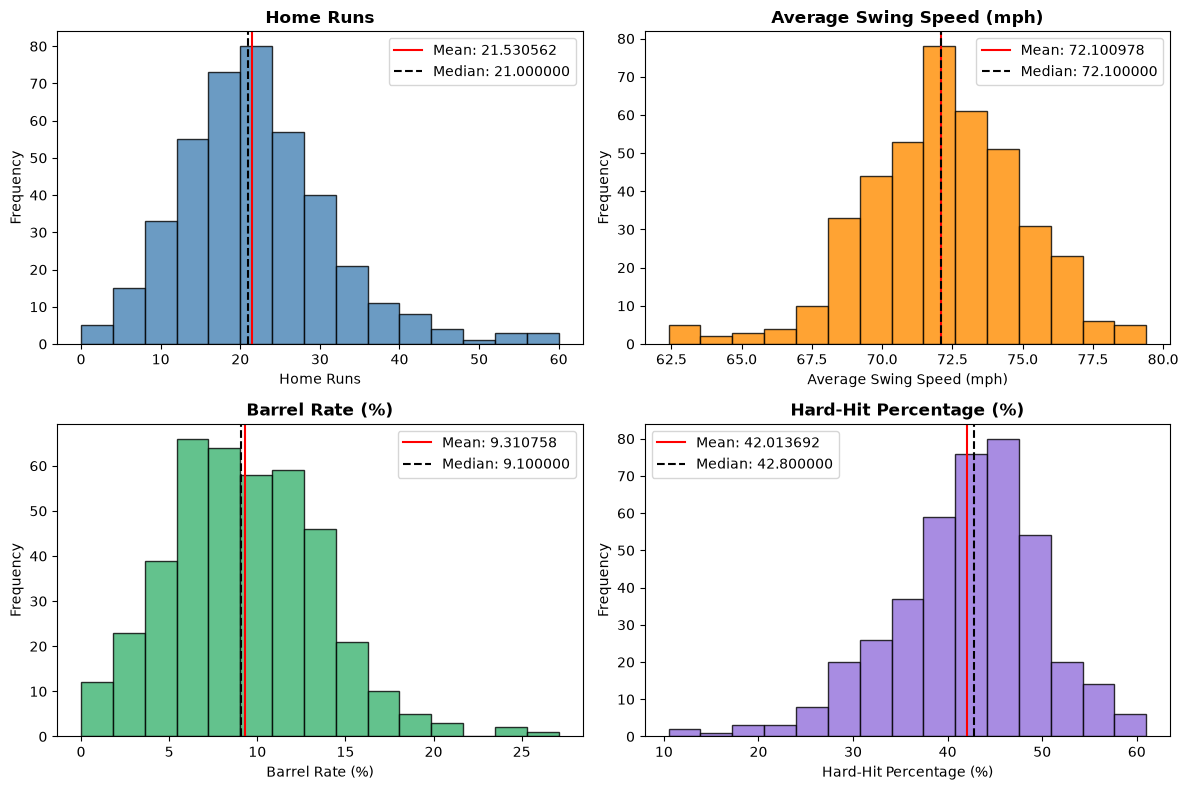

In [11]:
# Define clear titles for each batting statistic
titles = {
    "home_run": "Home Runs",
    "avg_swing_speed": "Average Swing Speed (mph)",
    "barrel_batted_rate": "Barrel Rate (%)",
    "hard_hit_percent": "Hard-Hit Percentage (%)",
}

# Create a 2x2 layout for the histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Create a histogram for each batting statistic
for column, colour, ax in zip(batting_columns, colours, axes.flat):

    # Display the distribution
    ax.hist(df[column], bins=15, color=colour,
            edgecolor="black", alpha=0.8)

    # Calculate the mean and median
    mean = df[column].mean()
    median = df[column].median()

    # Add the mean and median reference lines
    ax.axvline(mean, color="red", linestyle="-",
            label=f"Mean: {mean:2f}")
    ax.axvline(median, color="black", linestyle="--",
            label=f"Median: {median:2f}")

    # Add titles, axis labels and legend
    ax.set_title(titles[column], fontsize=12, fontweight="bold")
    ax.set_xlabel(titles[column])
    ax.set_ylabel("Frequency")
    ax.legend()

# Adjust spacing and display the histograms
plt.tight_layout()
plt.show()

### 4.2 Batting Statistics and Home Runs

The relationship between selected betting statistics and home-run totals will be examined using scatter plots. Barrel rate and hard-hit percentage will be compared against home runs to explore whether higher values are associated with greater home-run totals.

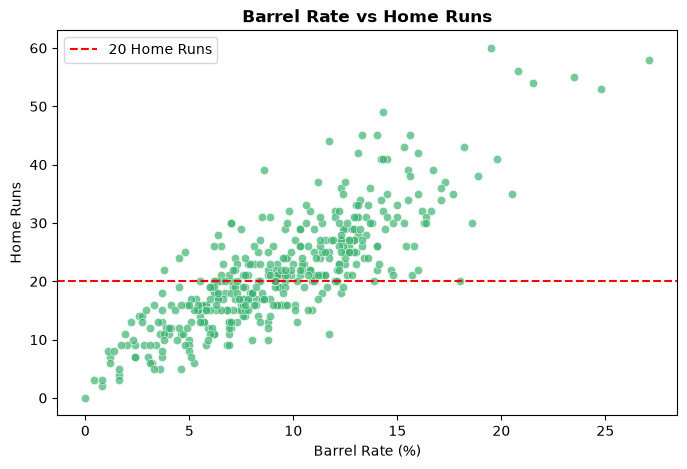

In [12]:
# Create a scatter plot comparing barrel rate and home runs
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="barrel_batted_rate", y="home_run",
                color="mediumseagreen", alpha=0.7)

# Add a reference line for the 20-home-run threshold
plt.axhline(y=20, color="red", linestyle="--",
            label="20 Home Runs")

# Add title, axis labels and legend
plt.title("Barrel Rate vs Home Runs", fontsize=12, fontweight="bold")
plt.xlabel("Barrel Rate (%)")
plt.ylabel("Home Runs")
plt.legend()

plt.tight_layout
plt.show()

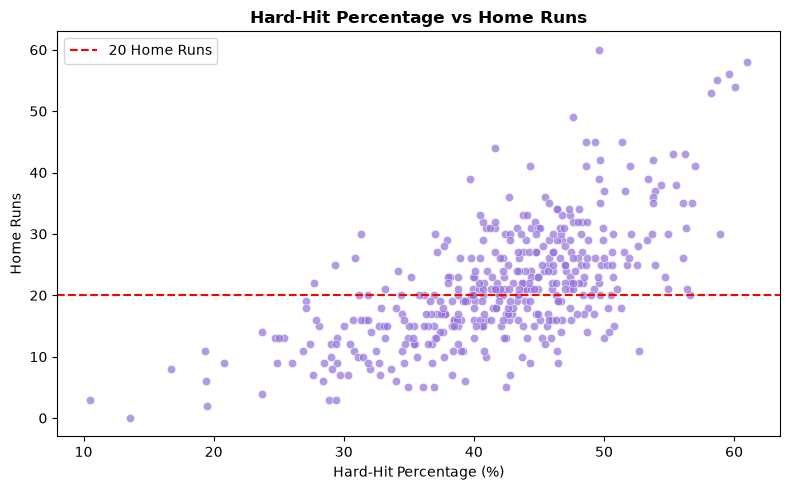

In [13]:
# Create a scatter plot comparing hard-hit percentage and home runs
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="hard_hit_percent", y="home_run",
                color="mediumpurple", alpha=0.7)

# Add a reference line for the 20-home-run threshold
plt.axhline(y=20, color="red", linestyle="--",
            label="20 Home Runs")

# Add a title, axis labels and legend
plt.title("Hard-Hit Percentage vs Home Runs", fontsize=12, fontweight="bold")
plt.xlabel("Hard-Hit Percentage (%)")
plt.ylabel("Home Runs")
plt.legend()

plt.tight_layout()
plt.show()

### 4.3 Relationships Between Batting Statistics

The relationships between selected batting statistics will be exmained using scatter plots. Average swing speed will be compared with hard-hit percentage, while barrel rate will be compared with hard-hit percentage. This will help identify potential relationships between the variables before machine learning.

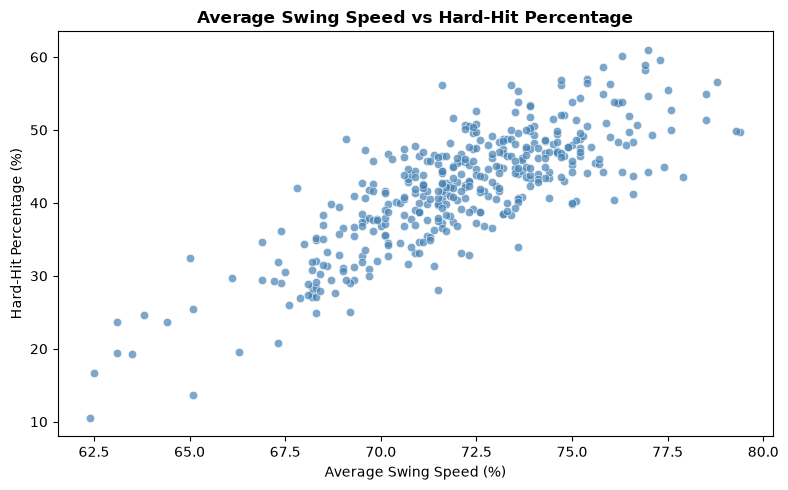

In [14]:
# Create a scatter plot comparing swing speed and hard-hit percentage
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="avg_swing_speed", y="hard_hit_percent",
                color="steelblue", alpha=0.7)

# Add a title, axis labels and legend
plt.title("Average Swing Speed vs Hard-Hit Percentage", 
          fontsize=12, fontweight="bold")
plt.xlabel("Average Swing Speed (%)")
plt.ylabel("Hard-Hit Percentage (%)")

plt.tight_layout()
plt.show()

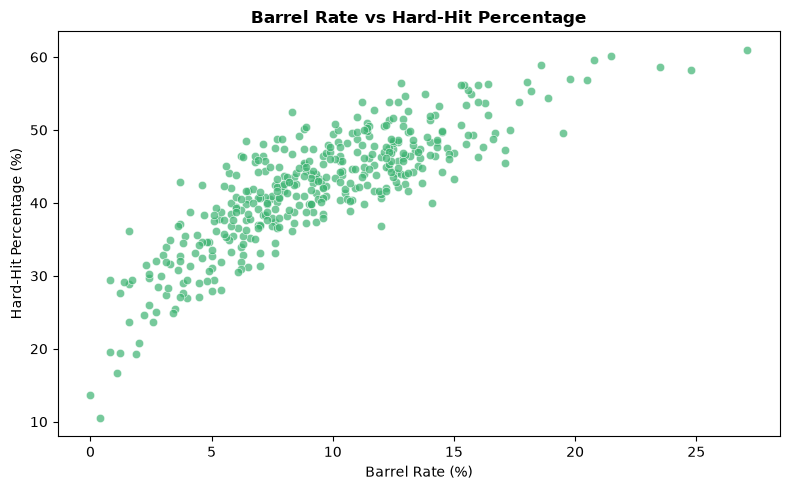

In [15]:
# Create a scatter plot comparing barrel rate and hard-hit percentage
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="barrel_batted_rate", y="hard_hit_percent",
                color="mediumseagreen", alpha=0.7)

# Add a title, axis labels and legend
plt.title("Barrel Rate vs Hard-Hit Percentage", 
          fontsize=12, fontweight="bold")
plt.xlabel("Barrel Rate (%)")
plt.ylabel("Hard-Hit Percentage (%)")

plt.tight_layout()
plt.show()

### 4.4 Correlation Anaylsis

Correlation analysis will be carried out to examine the strength and direction of relationships between selected batting statistics. Spearman's rank correlation coefficient will be used to calculate a correlation matrix, which will then be visualised using a heatmap. This method will help identify monotonic relationships between variables and potential overlap among the features.

In [16]:
# Select batting statistics for correlation analysis
correlation_columns = [
    "pa",
    "home_run",
    "avg_swing_speed",
    "fast_swing_rate",
    "launch_angle_avg",
    "sweet_spot_percent",
    "barrel_batted_rate",
    "hard_hit_percent",
    "whiff_percent",
    "swing_percent",
]

In [17]:
# Calculate Spearman's rank correlation coefficients
correlation_matrix = df[correlation_columns].corr(method="spearman")

# Display the correlation matrix rounded to two decimal places
correlation_matrix.round(2)

,pa,home_run,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
pa,1.00,0.42,0.15,0.17,0.02,0.14,0.19,0.20,0.05,-0.03
home_run,0.42,1.00,0.59,0.59,0.34,0.12,0.82,0.64,0.53,0.10
avg_swing_speed,0.15,0.59,1.00,0.99,-0.03,-0.14,0.75,0.77,0.60,0.06
fast_swing_rate,0.17,0.59,0.99,1.00,-0.05,-0.14,0.73,0.76,0.59,0.06
launch_angle_avg,0.02,0.34,-0.03,-0.05,1.00,0.32,0.23,-0.11,0.11,-0.01
sweet_spot_percent,0.14,0.12,-0.14,-0.14,0.32,1.00,0.17,0.03,-0.02,-0.04
barrel_batted_rate,0.19,0.82,0.75,0.73,0.23,0.17,1.00,0.82,0.70,0.04
hard_hit_percent,0.20,0.64,0.77,0.76,-0.11,0.03,0.82,1.00,0.54,-0.01
whiff_percent,0.05,0.53,0.60,0.59,0.11,-0.02,0.70,0.54,1.00,0.26
swing_percent,-0.03,0.10,0.06,0.06,-0.01,-0.04,0.04,-0.01,0.26,1.00


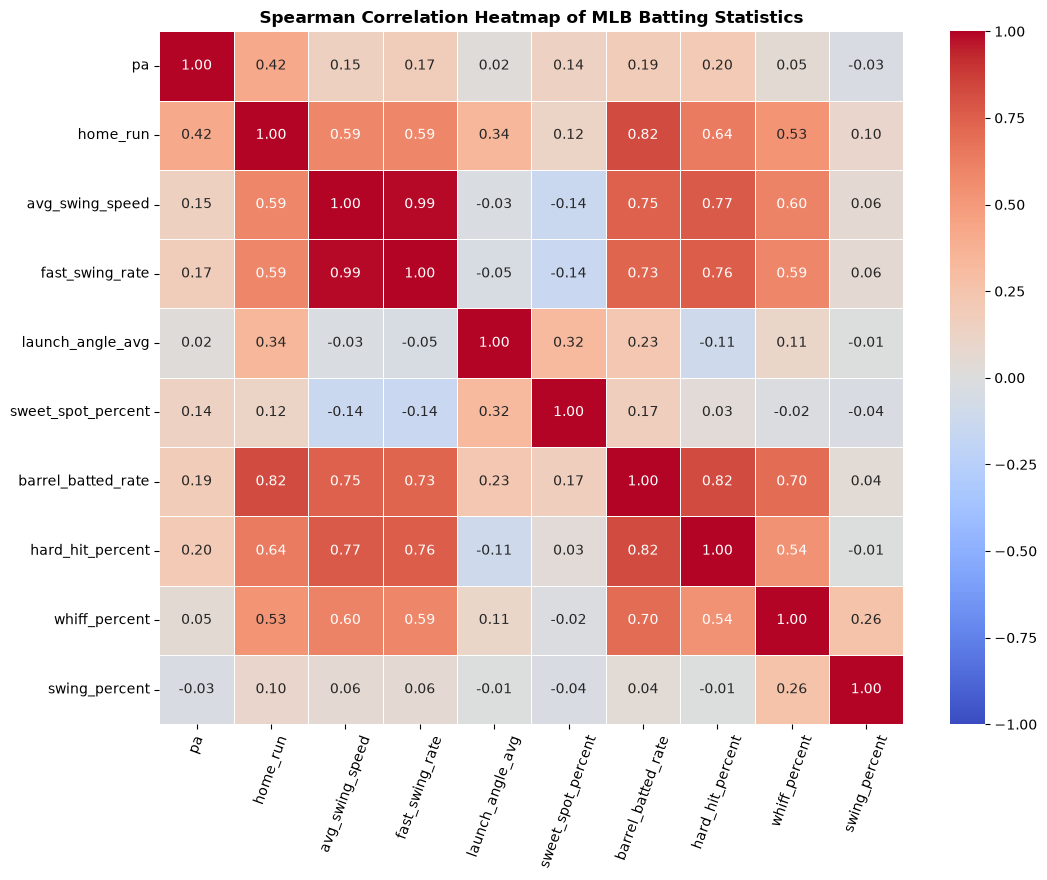

In [18]:
# Create a correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidth=0.5
)

# Add title and adjust layout
plt.title("Spearman Correlation Heatmap of MLB Batting Statistics",
          fontsize=12, fontweight="bold")

plt.xticks(rotation=70)
plt.tight_layout
plt.show()

### 4.5 Outlier Detection

Boxplots will be used to examine selected batting statistics and identify potential outliers within the dataset. The Interquartiles (IQR) method will also be applied to calculate outlier boundaries and identify values outside these ranges. This will help assess unusual observations before preparing the data for machine learning.

In [19]:
# Select batting statistics for outlier detection
outlier_columns = [
    "home_run",
    "avg_swing_speed",
    "barrel_batted_rate",
    "hard_hit_percent"
]

# Assign a different colour to each box plot
outlier_colours = [
"steelblue",
"orange",
"mediumseagreen",
"mediumpurple"
]

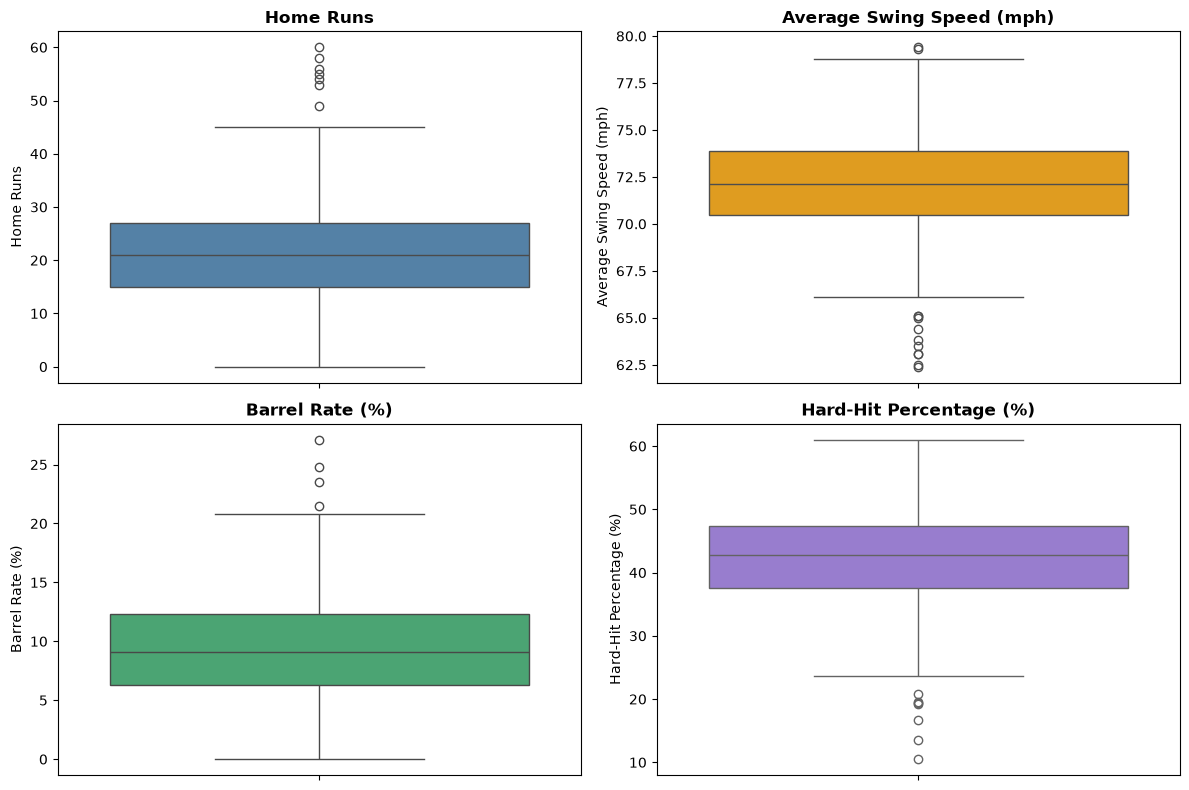

In [20]:
# Define clear titles for the box plots
outlier_titles = {
    "home_run": "Home Runs",
    "avg_swing_speed": "Average Swing Speed (mph)",
    "barrel_batted_rate": "Barrel Rate (%)",
    "hard_hit_percent": "Hard-Hit Percentage (%)"
}

# Create a 2x2 layout for the box plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Create a box plot for each batting statistic
for column, colour, ax in zip(outlier_columns, outlier_colours, axes.flat):

    # Display the box plots
    sns.boxplot(data=df, y=column, ax=ax, color=colour)

    # Add title and axis labels
    ax.set_title(outlier_titles[column], fontsize=12, fontweight="bold")
    ax.set_ylabel(outlier_titles[column])
    ax.set_xlabel("")

# Adjusting spacing and display the box plots
plt.tight_layout()
plt.show()

In [21]:
# Calculate the first and third quartiles
Q1 = df[outlier_columns].quantile(0.25)
Q3 = df[outlier_columns].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower and upper quartile boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers for each batting statistic
outlier_count = (
    (df[outlier_columns] < lower_bound) |
    (df[outlier_columns] > upper_bound)
).sum()

# Display the results in a table
outlier_summary = pd.DataFrame({
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": outlier_count
})

outlier_summary.round(2)

,Lower Bound,Upper Bound,Outlier Count
home_run,-3.00,45.00,7
avg_swing_speed,65.40,79.00,12
barrel_batted_rate,-2.70,21.30,4
hard_hit_percent,23.05,61.85,7


## 5. Data Cleaning and Preparation

The MLB batting dataset will be prepared for machine learning classification. A binary target will be created to identify whether a player hit 20 or more home runs in a season. Relevant input features will then be selected, while identifiers and variables that could cause data leakage will be excluded.

### 5.1 Creating the Target Variable

A binary target variable will be created using home-run totals in the dataset. Player-season records with 20 or more home runs will be assigned a vlaue of 1, while those with fewer than 20 will be assigned a value of 0. The distribution of both classes will be examined.

In [22]:
# Create a binary classification target
# 1 = 20 or more home runs
# 0 = Fewer than 20 home runs

df["home_run_20_plus"] = (df["home_run"] >=20).astype(int)

# Display the first five records
df[["home_run", "home_run_20_plus"]].head()

,home_run,home_run_20_plus
0,17,0
1,24,1
2,21,1
3,19,0
4,23,1


In [23]:
# Count the number of records in each classification
class_counts = df["home_run_20_plus"].value_counts().sort_index()

#
print("Class Distribution:")
print(class_counts)

# Display the total number of records
print("Total Records:", class_counts.sum())

Class Distribution:
home_run_20_plus
0    181
1    228
Name: count, dtype: int64
Total Records: 409


### 5.2 Selecting Input Features

Relevant batting and swing statistics will be selected as input features for the classification models. Player identifiers, season information and the original home-run totals will be excluded to avoid using irrelevant identifiers or introducing target leakage. The selected features will then be examined before model training.

In [24]:
# Select batting statisitics to use as input features
feature_columns = [
    "player_age",
    "pa",
    "avg_swing_speed",
    "fast_swing_rate",
    "launch_angle_avg",
    "sweet_spot_percent",
    "barrel_batted_rate",
    "hard_hit_percent",
    "whiff_percent",
    "swing_percent",
]

# Display the first five records of the selected features
df[feature_columns].head()

,player_age,pa,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
0,29,602,70.8,13.4,8.6,29.9,5.3,37.8,26.6,49.1
1,23,584,74.6,45.5,12.2,39.1,13.4,47.1,26.8,44.3
2,26,567,70.2,11.2,17.2,36.4,11.3,39.9,28.4,45.2
3,34,614,71.9,22.2,9.4,29.2,9.3,37.4,25.3,49.1
4,31,663,73.2,34.7,11.2,33.7,9.2,47.4,23.4,44.8


### 5.3 Checking the Prepared Dataset

The selected input features and binary target variable will be checked to confirm their data types, number of observations and completeness. This will help ensure that the prepared data is suitable for the classification models.

In [25]:
# Check the selected features and binary target variable
df[feature_columns + ["home_run_20_plus"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 409 entries, 0 to 408
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   player_age          409 non-null    int64  
 1   pa                  409 non-null    int64  
 2   avg_swing_speed     409 non-null    float64
 3   fast_swing_rate     409 non-null    float64
 4   launch_angle_avg    409 non-null    float64
 5   sweet_spot_percent  409 non-null    float64
 6   barrel_batted_rate  409 non-null    float64
 7   hard_hit_percent    409 non-null    float64
 8   whiff_percent       409 non-null    float64
 9   swing_percent       409 non-null    float64
 10  home_run_20_plus    409 non-null    int64  
dtypes: float64(8), int64(3)
memory usage: 35.3 KB


### 5.4 Defining Features (X) and Target Variable (y)

The selected batting statistics will be assigned to X as the input features, while the binary home-run classification variable will be assigned to y as the target. These variables will be used to train and evaluate the Decision Tree and Random Forest classification models.

In [26]:
# Define the input features (X)
X = df[feature_columns]
 
# Define the target varibale (y)
y = df["home_run_20_plus"]

# Display the dimensions of X and y
print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

Input Features (X): (409, 10)
Target Variable (y): (409,)


### 6 Training and Testing the Dataset

The prepared MLB batting dataset will be divided into training and testing sets to evaluate the performance of the classification models. Three different test sizes (5%), (15%) and (25%) will be examained, as required by the assignment. The Decision Tree and Random Forest classifiers will be trained and evaluated using these splits, with cross-validation used to assess the readability of their performance.

### 6.1 Splitting the Dataset

The input feature (X) and the target variable (y) will be divided into training and testing sets using test sizes of 5%, 15% and 25%. Stratified splitting will be used to main similiar proportions of both target classes, while a fixed random state will ensure probability.

In [27]:
# Import the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Split the dataset using 5% for testing and 95% for training
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X,
    y,
    test_size=0.05,
    random_state=23,
    stratify=y
)

# Display the number of training and test records
print("5% Test Split")
print("Training Records:", X_train_5.shape[0])
print("Testing Records:", X_test_5.shape[0])

5% Test Split
Training Records: 388
Testing Records: 21


In [28]:
# Split the dataset using 15% for testing and 85% for training
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=23,
    stratify=y
)

# Display the number of training and test records
print("15% Test Split")
print("Training Records:", X_train_15.shape[0])
print("Testing Records:", X_test_15.shape[0])

15% Test Split
Training Records: 347
Testing Records: 62


In [29]:
# Split the dataset using 25% for testing and 75% for training
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=23,
    stratify=y
)

# Display the number of training and test records
print("25% Test Split")
print("Training Records:", X_train_25.shape[0])
print("Testing Records:", X_test_25.shape[0])

25% Test Split
Training Records: 306
Testing Records: 103


### 6.2 Checking Class Distribution

The distribution of the target class will be examined across the training and testing sets for each test split. The percentage of records belonging to each class will be calculated to check whether stratified splitting has maintained similiar class proportions.

In [30]:
# Check the class distribution for the 5% test split
print("5% Test Split - Class Distribution")

# Display the percentage of each class in the traininng set
print("Training Set (%):")
print(y_train_5.value_counts(normalize=True).sort_index().mul(100).round(2))

# Dsiplay the percenatge of each class in the testing data
print("Testing Set (%):")
print(y_test_5.value_counts(normalize=True).sort_index().mul(100).round(2))

5% Test Split - Class Distribution
Training Set (%):
home_run_20_plus
0    44.33
1    55.67
Name: proportion, dtype: float64
Testing Set (%):
home_run_20_plus
0    42.86
1    57.14
Name: proportion, dtype: float64


In [31]:
# Check the class distribution for the 15% test split
print("15% Test Split - Class Distribution")

# Display the percentage of each class in the traininng set
print("Training Set (%):")
print(y_train_15.value_counts(normalize=True).sort_index().mul(100).round(2))

# Dsiplay the percenatge of each class in the testing data
print("Testing Set (%):")
print(y_test_15.value_counts(normalize=True).sort_index().mul(100).round(2))

15% Test Split - Class Distribution
Training Set (%):
home_run_20_plus
0    44.38
1    55.62
Name: proportion, dtype: float64
Testing Set (%):
home_run_20_plus
0    43.55
1    56.45
Name: proportion, dtype: float64


In [32]:
# Check the class distribution for the 25% test split
print("25% Test Split - Class Distribution")

# Display the percentage of each class in the traininng set
print("Training Set (%):")
print(y_train_25.value_counts(normalize=True).sort_index().mul(100).round(2))

# Dsiplay the percenatge of each class in the testing data
print("Testing Set (%):")
print(y_test_25.value_counts(normalize=True).sort_index().mul(100).round(2))

25% Test Split - Class Distribution
Training Set (%):
home_run_20_plus
0    44.12
1    55.88
Name: proportion, dtype: float64
Testing Set (%):
home_run_20_plus
0    44.66
1    55.34
Name: proportion, dtype: float64


### 7. Decision Tree and Random Forest Classification Models

Two supervised learning classification models, Decision Tree and Random Forest, will be developed to predict whether an MLB player hits 20 or more home runs in a season. Both models will be trained using the training datasets created in Section (95%, 85% and 75%) and will generate predictions usingtheir corresponding testing datasets. Their performance will then be evaluated and compared.

### 7.1 Impprting the Classification Models

The Decision Tree and Random Forest classification classifiers will be imported from Scikit-learn. These supervised learning algorithms will be used to classify MLB player-season records based on the selected batting statistics.

In [33]:
# Import the Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Import the Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

### 7.2 Training the Decision Tree Classifier 

A Decision Tree classifier will be trained using each of the three training datasets (95%, 85% and 75%). The model will learn patterns from the selected batting statistics to classify whether a player hits 20 or more home runs in a season. A fixed random state will be used to ensure reproducibility.

In [34]:
# Create a Decision Tree classifier from the 5% test split
dt_5 = DecisionTreeClassifier(random_state=23)

# Train the classifier using the 95% training dataset
dt_5.fit(X_train_5, y_train_5)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",23
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [35]:
# Create a Decision Tree classifier from the 15% test split
dt_15 = DecisionTreeClassifier(random_state=23)

# Train the classifier using the 85% training dataset
dt_15.fit(X_train_15, y_train_15)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",23
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [36]:
# Create a Decision Tree classifier from the 25% test split
dt_25 = DecisionTreeClassifier(random_state=23)

# Train the classifier using the 75% training dataset
dt_25.fit(X_train_25, y_train_25)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",23
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

### 7.3 Training the Random Forest Classifier 

A Random Forest Classifer will be trained using each of the three training datasets (95%, 85% and 75%). The model will combine decision trees to classify whether a player hits 20 or more home runs in a season. A fixed random state will be used to ensure reproducibility.

In [37]:
# Create a Random Forest Classifier for the 5% test split
rf_5 = RandomForestClassifier(random_state=23)

# Train the classifier using the 95% training dataset
rf_5.fit(X_train_5, y_train_5)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",23
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [38]:
# Create a Random Forest Classifier for the 15% test split
rf_15 = RandomForestClassifier(random_state=23)

# Train the classifier using the 85% training dataset
rf_15.fit(X_train_15, y_train_15)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",23
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [39]:
# Create a Random Forest Classifier for the 25% test split
rf_25 = RandomForestClassifier(random_state=23)

# Train the classifier using the 75% training dataset
rf_25.fit(X_train_25, y_train_25)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",23
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

### 7.4 Generating Model Predictions

The trained Decision tree and Random Forest classifiers will be used to generate predictions for their corresponding testing datasets. Each prediction will classify a player-season record as either 0 (fewer than 20 home runs) or 1 (20 or more home runs). These predictions will be used to evaluate and compare model performance.

In [40]:
# Generate Decision Tree predictions for the 5% test split
dt_pred_5 = dt_5.predict(X_test_5)

# Generate Random Forest predictions for the 5% test split
rf_pred_5 = rf_5.predict(X_test_5)

In [41]:
# Generate Decision Tree predictions for the 15% test split
dt_pred_15 = dt_15.predict(X_test_15)

# Generate Random Forest predictions for the 15% test split
rf_pred_15 = rf_15.predict(X_test_15)

In [42]:
# Generate Decision Tree predictions for the 25% test split
dt_pred_25 = dt_25.predict(X_test_25)

# Generate Random Forest predictions for the 25% test split
rf_pred_25 = rf_25.predict(X_test_25)

### 8. Cross-Validation and Model Comparison

The performance of the Decision Tree and Random Forest classifiers will be evaluated using the 5%, 15% and 25% test splits. Classification accuracy will be calculated by comapring model predictions with the actual target values. Corss-validation will also be performed on the training data to assess the consistency and reliability of both models.

### 8.1 Calculating Model Accuracy

Classification accuracy will be calculated for the Decision Tree and Random Forest models using each testing dataset. the predicted calculations will be comapred with the actual values to determine the percentage of correct predictions for each model.

In [43]:
# Import the function for calculating classification accuracy
from sklearn.metrics import accuracy_score

In [44]:
# Calculating accuracy for the 5% Decision Tree model
dt_accuracy_5 = accuracy_score(y_test_5, dt_pred_5)

# Calculating accuracy for the 5% Random Forest model
rf_accuracy_5 = accuracy_score(y_test_5, rf_pred_5)

# Display accuracy as percentages
print("5% Test Split")
print("Decision Tree Accuracy:", round(dt_accuracy_5* 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy_5* 100, 2), "%")

5% Test Split
Decision Tree Accuracy: 76.19 %
Random Forest Accuracy: 100.0 %


In [45]:
# Calculating accuracy for the 15% Decision Tree model
dt_accuracy_15 = accuracy_score(y_test_15, dt_pred_15)

# Calculating accuracy for the 15% Random Forest model
rf_accuracy_15 = accuracy_score(y_test_15, rf_pred_15)

# Display accuracy as percentages
print("15% Test Split")
print("Decision Tree Accuracy:", round(dt_accuracy_15* 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy_15* 100, 2), "%")

15% Test Split
Decision Tree Accuracy: 82.26 %
Random Forest Accuracy: 93.55 %


In [46]:
# Calculating accuracy for the 25% Decision Tree model
dt_accuracy_25 = accuracy_score(y_test_25, dt_pred_25)

# Calculating accuracy for the 25% Random Forest model
rf_accuracy_25 = accuracy_score(y_test_25, rf_pred_25)

# Display accuracy as percentages
print("25% Test Split")
print("Decision Tree Accuracy:", round(dt_accuracy_25* 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy_25* 100, 2), "%")

25% Test Split
Decision Tree Accuracy: 80.58 %
Random Forest Accuracy: 88.35 %


### 8.2 Cross-Validation

Five fold cross-validation will be perfromed on the training datasets for both classification models. Each model will be evaluated across five folds, and the mean accuracy and standard deviation will be calculated to assess the consistency of its performance.

In [47]:
# Import the function for cross-validation
from sklearn.model_selection import cross_val_score

In [48]:
# Perform five-fold cross-validation for the Decision Tree
dt_cv_5 = cross_val_score(
    dt_5, X_train_5, y_train_5, cv=5, scoring="accuracy"
)


# Perform five-fold cross-validation for the Random Forest
rf_cv_5 = cross_val_score(
    rf_5, X_train_5, y_train_5, cv=5, scoring="accuracy"
)

In [49]:
# Display the mean accuracy and standard deviation
print("5% Test Split - Cross-Validation")
print("Decision Tree Mean Accuracy:", round(dt_cv_5.mean() * 100, 2), "%")
print("Decision Tree Stanard Deviation:", round(dt_cv_5.std() * 100, 2), "%")
print("Random Forest Mean Accuracy:", round(rf_cv_5.mean() * 100, 2), "%")
print("Random Forest Standard Deviation:", round(rf_cv_5.std() * 100, 2), "%")

5% Test Split - Cross-Validation
Decision Tree Mean Accuracy: 76.83 %
Decision Tree Stanard Deviation: 5.75 %
Random Forest Mean Accuracy: 84.56 %
Random Forest Standard Deviation: 3.83 %


In [50]:
# Perform five-fold cross-validation for the Decision Tree
dt_cv_15 = cross_val_score(
    dt_15, X_train_15, y_train_15, cv=5, scoring="accuracy"
)


# Perform five-fold cross-validation for the Random Forest
rf_cv_15 = cross_val_score(
    rf_15, X_train_15, y_train_15, cv=5, scoring="accuracy"
)

In [51]:
# Display the mean accuracy and standard deviation
print("15% Test Split - Cross-Validation")
print("Decision Tree Mean Accuracy:", round(dt_cv_15.mean() * 100, 2), "%")
print("Decision Tree Stanard Deviation:", round(dt_cv_15.std() * 100, 2), "%")
print("Random Forest Mean Accuracy:", round(rf_cv_15.mean() * 100, 2), "%")
print("Random Forest Standard Deviation:", round(rf_cv_15.std() * 100, 2), "%")

15% Test Split - Cross-Validation
Decision Tree Mean Accuracy: 75.23 %
Decision Tree Stanard Deviation: 2.14 %
Random Forest Mean Accuracy: 84.17 %
Random Forest Standard Deviation: 3.65 %


In [52]:
# Perform five-fold cross-validation for the Decision Tree
dt_cv_25 = cross_val_score(
    dt_25, X_train_25, y_train_25, cv=5, scoring="accuracy"
)


# Perform five-fold cross-validation for the Random Forest
rf_cv_25 = cross_val_score(
    rf_25, X_train_25, y_train_25, cv=5, scoring="accuracy"
)

In [53]:
# Display the mean accuracy and standard deviation
print("25% Test Split - Cross-Validation")
print("Decision Tree Mean Accuracy:", round(dt_cv_25.mean() * 100, 2), "%")
print("Decision Tree Stanard Deviation:", round(dt_cv_25.std() * 100, 2), "%")
print("Random Forest Mean Accuracy:", round(rf_cv_25.mean() * 100, 2), "%")
print("Random Forest Standard Deviation:", round(rf_cv_25.std() * 100, 2), "%")

25% Test Split - Cross-Validation
Decision Tree Mean Accuracy: 79.42 %
Decision Tree Stanard Deviation: 2.8 %
Random Forest Mean Accuracy: 83.01 %
Random Forest Standard Deviation: 3.2 %


### 8.3 Comapring Model Performance

The test accuracy, mean cross-validation and standard deviation of the Decision Tree and Random Forest classifiers will be compared across the three test splits. The results, will be presented in a table to examine differences in model performance.

In [54]:
# Create a table comapring both models across the three test splits
comparison_results = pd.DataFrame({
    "Test Split": ["5%", "5%", "15%", "15%", "25%", "25%"],
    "Model": [
        "Decision Tree", "Random Forest",
        "Decision Tree", "Random Forest",
        "Decision Tree", "Random Forest"
    ],
    "Test Accuracy (%)": [
        dt_accuracy_5 * 100, rf_accuracy_5 * 100,
        dt_accuracy_15 * 100, rf_accuracy_15 * 100,
        dt_accuracy_25 * 100, rf_accuracy_25 * 100
    ],
    "CV Mean Accuracy (%)": [
        dt_cv_5.mean() * 100, rf_cv_5.mean() * 100,
        dt_cv_15.mean() * 100, rf_cv_15.mean() * 100,
        dt_cv_25.mean() * 100, rf_cv_25.mean() * 100
    ],
    "CV Standard Deviation (%)": [
        dt_cv_5.std() * 100, rf_cv_5.std() * 100,
        dt_cv_15.std() * 100, rf_cv_15.std() * 100,
        dt_cv_25.std() * 100, rf_cv_25.std() * 100
    ]
})

In [55]:
# Display the comparison table rounded to two decimal places
comparison_results.round(2)

,Test Split,Model,Test Accuracy (%),CV Mean Accuracy (%),CV Standard Deviation (%)
0,5%,Decision Tree,76.19,76.83,5.75
1,5%,Random Forest,100.00,84.56,3.83
2,15%,Decision Tree,82.26,75.23,2.14
3,15%,Random Forest,93.55,84.17,3.65
4,25%,Decision Tree,80.58,79.42,2.80
5,25%,Random Forest,88.35,83.01,3.20


## 9. Hyperparameter Tuning

Hyperparameter tuning will be performed using GridSerachCV to identify suitable settings for the Decision Tree and Random Forest classifiers. Five-fold cross-validation will be used to evaluate different parameter combinations. Tuning will be carried out using the 75% training dataset, with the remaining 25% reserved for testing the optimised models.

### 9.1 Defining the Hyperparameter Grids

Hyperparameter grids will be defined for the Decision Tree and Random Forest classifiers. The grids will specify different values for tree depth, minimum samples required for splitting and minimum samples per leaf. The Random Forest grid will also include the number of trees. These combinations will be evaluated using GridSearchCV. 

In [56]:
# Defining hyperparamter grids for each classifier
param_grids = {
    "Decision Tree": {
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },
    "Random Forest": {
        "n_estimators": [50, 100],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    }
}

### 9.2 Applying GridSearchCV

GridsearchCV wiil be applied to the Decision Tree and Random Forest classifiers using the hyperparameter grids defined in subsection 9.1. five-fold cross-validation will be performed on the 75% training dataset to identify the best parameter combinations for each model. The optimal parameters and mean cross-validation accuracy will then be displayed.

In [57]:
from sklearn.model_selection import GridSearchCV

In [58]:
# Apply GridSearchCV to the Decision Tree Classsifier
dt_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=23),
    param_grid=param_grids["Decision Tree"],
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [59]:
# Fit GridSearchCV using the 75% training dataset
dt_grid_search.fit(X_train_25, y_train_25)

# Display the best parameters and cross-validation accuracy
print("Decision Tree = GridSearchCV")
print("Best Parameters:", dt_grid_search.best_params_)
print("Best CV Accuracy:", round(dt_grid_search.best_score_* 100, 2), "%")

Decision Tree = GridSearchCV
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Accuracy: 79.42 %


In [60]:
# Apply GridSearchCV to the Random Forest Classsifier
rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=23),
    param_grid=param_grids["Random Forest"],
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [61]:
# Fit GridSearchCV using the 75% training dataset
rf_grid_search.fit(X_train_25, y_train_25)

# Display the best parameters and cross-validation accuracy
print("Random Forest = GridSearchCV")
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV Accuracy:", round(rf_grid_search.best_score_* 100, 2), "%")

Random Forest = GridSearchCV
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
Best CV Accuracy: 83.01 %


### 9.3 Evaluating the Tuned Models

The best Decision Tree and Random Forest classifers identified by GridSearchCV will be evaluated using the 25% testing dataset. Each model will generate predictions, which will be comapred with the actual target values to calculate classification accuracy. This will assess their performance on the data not used during training or hyperparameter tuning.

In [62]:
# Get the best Decision Tree model from GridSearchCV
dt_tuned = dt_grid_search.best_estimator_

# Generate predictions using the 25% training dataset
dt_tuned_pred = dt_tuned.predict(X_test_25)

# Calculate and display the tunded Decision Tree accuracy
dt_tuned_accuracy = accuracy_score(y_test_25, dt_tuned_pred)

print("Tuned Decision Tree")
print("Test Accuracy:", round(dt_tuned_accuracy * 100, 2), "%")

Tuned Decision Tree
Test Accuracy: 80.58 %


In [63]:
# Get the best Random Forest model from GridSearchCV
rf_tuned = rf_grid_search.best_estimator_

# Generate predictions using the 25% testing dataset
rf_tuned_pred = rf_tuned.predict(X_test_25)

# Calculate and display the tunded Random Forest accuracy
rf_tuned_accuracy = accuracy_score(y_test_25, rf_tuned_pred)

print("Tuned Random Forest")
print("Test Accuracy:", round(rf_tuned_accuracy * 100, 2), "%")

Tuned Random Forest
Test Accuracy: 88.35 %


### 9.4 Comparing Results Before and After Tuning

The original and tuned test accuracies of the Decision Tree and Random Forest classifiers will be compared using the 25% testing dataset. The results will be presented in a table to examine whether hyperparameter tuning improved the classification accuracy of either model.

In [64]:
# Create a table comparing accuracy before and after tuning
tuning_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Original Accuracy (%)": [
        dt_accuracy_25 * 100,
        rf_accuracy_25 * 100
    ],
    "Tuned Accuracy (%)": [
        dt_tuned_accuracy * 100,
        rf_tuned_accuracy * 100
    ]
})

# Calculate the change in accuracy in percentage points
tuning_comparison["Change (%)"] = (
    tuning_comparison["Tuned Accuracy (%)"] -
    tuning_comparison["Original Accuracy (%)"]
)

# Display the comparison table
tuning_comparison.round(2)

,Model,Original Accuracy (%),Tuned Accuracy (%),Change (%)
0,Decision Tree,80.58,80.58,0.0
1,Random Forest,88.35,88.35,0.0


## 10. Model Evaluation and Visualisations

The classification models will be evaluated using additional performance metrics and visualisations. Classification reports and a coonfusion matrix will be examined, alongside model accuracy to assess the performance of the Decision Tree and Random Forest classifers.

### 10.1 Model Evaluation

Classification reports and confusion matrices will be used to evaluate the tuned Decision Tree and Random Forest classifiers. Precision, recall and F1-score will be calculated to assess the classification performace. Confusion matrices will visualise the correct and incorrect predictions on the 25% testing dataset.

In [65]:
# Import the function for classification reports
from sklearn.metrics import classification_report

In [66]:
# Display the Decision Tree classification report
print("Tuned Decision Tree - classification report")
print(classification_report(y_test_25, dt_tuned_pred))

# Display the Random Forest classification report
print("Tuned Random Forest - classification report")
print(classification_report(y_test_25, rf_tuned_pred))

Tuned Decision Tree - classification report
              precision    recall  f1-score   support

           0       0.77      0.80      0.79        46
           1       0.84      0.81      0.82        57

    accuracy                           0.81       103
   macro avg       0.80      0.81      0.80       103
weighted avg       0.81      0.81      0.81       103

Tuned Random Forest - classification report
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        46
           1       0.89      0.89      0.89        57

    accuracy                           0.88       103
   macro avg       0.88      0.88      0.88       103
weighted avg       0.88      0.88      0.88       103



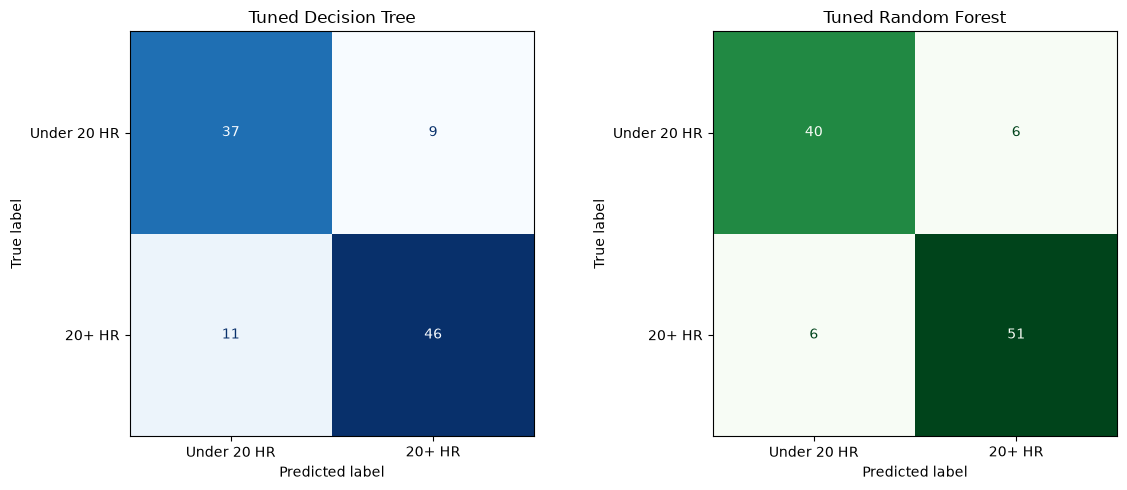

In [67]:
# Import the function for the confusion matrices
from sklearn.metrics import ConfusionMatrixDisplay

# Create two confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_25,
    dt_tuned_pred,
    display_labels=["Under 20 HR", "20+ HR"],
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Tuned Decision Tree")

# Random Forest confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_25,
    rf_tuned_pred,
    display_labels=["Under 20 HR", "20+ HR"],
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title("Tuned Random Forest")

plt.tight_layout()
plt.show()

### 10.2 Model Performance 

The accuracy of the Decision Tree and Random Forest classifiers will be compared across three test splits (5%, 15% and 25%). A bar chart will be used to visualise the difference in model performance.

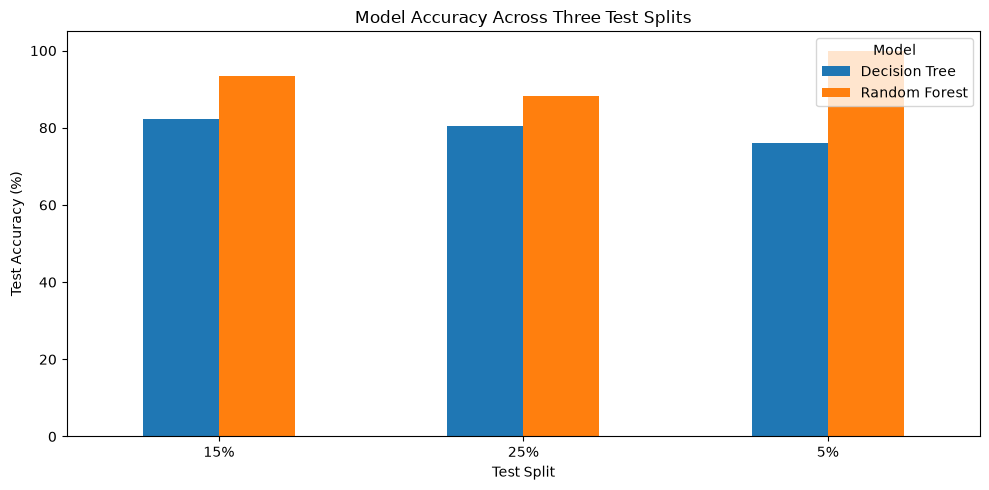

In [68]:
# Prepare the model accuracy results for visualisation
accuracy_comparison = comparison_results.pivot(
    index="Test Split",
    columns="Model",
    values="Test Accuracy (%)"
)

# Display the bar chart comparing model accuracy
accuracy_comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Model Accuracy Across Three Test Splits")
plt.xlabel("Test Split")
plt.xticks(rotation=0)
plt.ylabel("Test Accuracy (%)")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## References 

McQuiad, D. (2026) <em> 'Data Preparation Module Notes'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3680 (Access: 15 November 2026).

Eccher, C. (2026) <em> 'Statistical Techniques for Data Analysis'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3681 (Accessed: 15 November 2026).

Iqbal, M. (2026) <em> 'Machine Learning'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3682 (Accessed: 15 November 2026).

Ahmed, T. (2026) <em> 'Strategic Thinking'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3679 (Accessed: 15 November 2026).

Markdown Guide. (2026). <em> 'Basic Synthax'. </em> Available at: https://markdownguide.offshoot.io/basic-syntax/ (Accessed: 15 November 2026).

Major League Baseball (2026) <em> 'Baseball Savant: Custom Leaderboard - MLB Batting Statistics, 2024-2026'. </em> Available at: https://baseballsavant.mlb.com/leaderboard/custom?year=2026%2C2025%2C2024&type=batter&filter=&min=q&selections=player_age%2Cpa%2Chome_run%2Cavg_swing_speed%2Cfast_swing_rate%2Claunch_angle_avg%2Csweet_spot_percent%2Cbarrel_batted_rate%2Chard_hit_percent%2Cwhiff_percent%2Cswing_percent&chart=false&x=pa&y=pa&r=no&chartType=beeswarm&sort=player_name&sortDir=desc (Accessed: 15 November 2026).

pandas (2026) <em> 'pandas.DataFrame.duplicated'. </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html (Accessed: 15 November 2026).

pandas (2026) <em> 'pandas.DataFrame.hist'. </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html (Accessed: 15 November 2026).

Matplotlib Development Team (2026) <em> 'matplotlib.pyplot.tight_layout'. </em> Available at: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html (Accessed: 15 November 2026).

Matplotlib Development Team (2026) <em> 'matplotlib.pyplot.axhline' </em> Available at: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html (Accessed: 16 November 2026).

Matplotlib Development Team (2026) <em> 'Histograms' </em> Available at: https://matplotlib.org/stable/gallery/statistics/hist.html (Accessed: 16 November 2026).

Matplotlib Development Team (2026) <em> 'Create multiple subplots using plt.subplots' </em> Available at: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html (Accessed: 16 November 2026).

Matplotlib Development Team (2026) <em> 'matplotlib.axes.Axes.axvline' </em> Available at: Matplotlib Development Team (2026) <em> 'Create multiple subplots using plt.subplots' </em> Available at: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html (Accessed: 16 November 2026). (Accessed: 16 November 2026).

Seaborn (2024) <em> 'seaborn.scatterplots' </em> Available at: https://seaborn.pydata.org/generated/seaborn.scatterplot.html (Accessed: 16 November 2026).

Matplotlib Development Team (2026) <em> 'matplotlib.pyplot.axhline' </em> Available at: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html (Accessed: 16 November 2026).

Pandas (2026) <em> 'pandas.DataFrame.corr' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html (Accessed: 16 November 2026).

Seaborn (2024) <em> 'seaborn.heatmap' </em> Available at: https://seaborn.pydata.org/generated/seaborn.heatmap.html (Accessed: 16 November 2026).

Pandas (2026) <em> 'pandas.DataFrame.quantile' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html (Accessed 16 November 2026).

Seaborn (2024) <em> 'seaborn.boxplot' </em> Available at: https://seaborn.pydata.org/generated/seaborn.boxplot.html (Accessed: 16 November 2026).

Rice University (2026) <em> '2.3 Measures of the Location of the Data' </em> Available at: https://openstax.org/books/introductory-statistics-2e/pages/2-3-measures-of-the-location-of-the-data? (Accessed: 16 November 2026)>

Pandas (2026) <em> 'pandas.Series.astype' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.astype.html (Accessed: 16 November 2026).

Pandas (2026) <em> 'pandas.Series.value_counts' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html (Accessed: 16 November 2026).

scikit-learn developers (2026) <em> 'Supervise learning' </em> Available at: https://scikit-learn.org/stable/supervised_learning.html (Accessed: 16 November 2026).

scikit-learn developers (2026) <em> 'Comparing Target Encoder with Other Encoders' </em> Available at: https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder.html (Accessed: 16 November 2026).

scikit-learn developers (2026) <em> 'train_test_split' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html (Accessed 17 November 2026).

Pandas (2026) <em> 'pandas.Series.mul' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.mul.html (Accessed: 17 November 2026).

scikit-learn developers (2026) <em> 'DecisionTreeClassifier' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html (Accessed: 17 November 2026).

scikit-learn developers (2026) <em> 'RandomForestClassifier' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html (Accessed: 17 November 2026).

scikit-learn developers (2026) <em> 'accuracy_score' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html (Accessed: 17 November 2026).

scikit-learn developers (2026) <em> 'GridSearchCV' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html (Accessed: 18 November 2026).

scikit-learn developers (2026) <em> 'ConfusionMatrixDisplay' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html (Accessed: 18 November 2026).

scikit-learn developers (2026) <em> 'classification_report' </em> Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html (Accessed: 18 November 2026).

Matplotlib Development Team (2026) <em> 'Pyplot tutorial' </em> Available at: https://matplotlib.org/stable/tutorials/pyplot.html (Accessed: 18 November 2026).

Pandas (2026) <em> 'pandas.DataFrame.plot.bar' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html (Accessed: 18 November 2026).

Pandas (2026) <em> 'pandas.DataFrame.pivot' </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html (Accessed: 18 November 2026).